In [1]:
%pip -q install "qiskit>=2.0,<3" "qiskit[visualization]>=2.0,<3" scipy numpy pandas matplotlib pylatexenc tabulate

In [2]:
import time, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import qiskit

OUT = Path('qubo_homework_results'); OUT.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED)
print('Qiskit version:', qiskit.__version__)
print('Output folder:', OUT.resolve())

Qiskit version: 2.6.2
Output folder: /content/qubo_homework_results


In [3]:
# 고정된 4-정점 가중치 그래프 — 모든 알고리즘에 동일하게 사용
N = 4
EDGES = [(0,1,3.0), (0,2,2.0), (1,2,1.0), (1,3,2.0), (2,3,3.0)]

def make_qubo(n, edges):
    Q = np.zeros((n, n), dtype=float)
    for i,j,w in edges:
        Q[i,i] -= w
        Q[j,j] -= w
        Q[i,j] += w
        Q[j,i] += w
    return Q

def bitstr(index, n):
    return format(index, f'0{n}b')

def bits(index, n):
    # x_i 는 i번째 큐비트에 대응 (오른쪽 비트부터)
    return np.array([(index >> i) & 1 for i in range(n)], dtype=int)

def energy(index, Q):
    x = bits(index, Q.shape[0]); return float(x @ Q @ x)

Q = make_qubo(N, EDGES)
energies = np.array([energy(i, Q) for i in range(2**N)])
optimum_energy = float(energies.min())
opt_indices = np.flatnonzero(np.isclose(energies, optimum_energy))
print('QUBO matrix Q:\n', Q)
print('Global minimum energy:', optimum_energy)
print('Optimal bitstrings:', [bitstr(i,N) for i in opt_indices])
assert all(np.isclose(energy(k,Q), -sum(w * (((k>>i)&1) != ((k>>j)&1)) for i,j,w in EDGES)) for k in range(2**N))

QUBO matrix Q:
 [[-5.  3.  2.  0.]
 [ 3. -6.  1.  2.]
 [ 2.  1. -6.  3.]
 [ 0.  2.  3. -5.]]
Global minimum energy: -10.0
Optimal bitstrings: ['0110', '1001']


In [4]:
def uniform_circuit(n):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    return qc

def qaoa_circuit(n, edges, gamma, beta):
    qc = uniform_circuit(n)
    qc.barrier()
    for i,j,w in edges:
        qc.rzz(gamma*w, i, j)
    qc.barrier()
    for i in range(n):
        qc.rx(2*beta, i)
    return qc

def probs(qc):
    # 측정 게이트를 추가하지 않은 회로로 정확한 Statevector 계산
    sv = Statevector.from_instruction(qc)
    return np.abs(sv.data)**2

def expected_energy(qc, energies):
    return float(np.dot(probs(qc), energies))

qc_a = uniform_circuit(N)
prob_a = probs(qc_a)
print('A state circuit:\n', qc_a.draw(output='text'))
print('A normalized:', np.isclose(prob_a.sum(), 1.0))

A state circuit:
      ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     ├───┤
q_2: ┤ H ├
     ├───┤
q_3: ┤ H ├
     └───┘
A normalized: True


In [5]:
# 동일한 실험을 재현하기 위해 초기값을 고정합니다.
# 목적함수 = 상태 B의 기대 QUBO 에너지 (낮을수록 좋음)
objective_calls = {'n': 0}
def objective(theta):
    objective_calls['n'] += 1
    return expected_energy(qaoa_circuit(N, EDGES, *theta), energies)

t0 = time.perf_counter()
starts = [[0.6,0.4], [1.4,0.7], [2.5,1.0], [4.2,0.5], [5.4,1.2]]
fits = [minimize(objective, x0=start, method='Nelder-Mead',
                 options={'maxiter':250, 'xatol':1e-7, 'fatol':1e-7}) for start in starts]
best_fit = min(fits, key=lambda fit: fit.fun)
qaoa_training_seconds = time.perf_counter() - t0
gamma_opt, beta_opt = map(float, best_fit.x)
qc_b = qaoa_circuit(N, EDGES, gamma_opt, beta_opt)
prob_b = probs(qc_b)
print(f'Optimized gamma={gamma_opt:.5f}, beta={beta_opt:.5f}')
print('QAOA expected energy:', expected_energy(qc_b, energies))
print('QAOA optimization wall time:', round(qaoa_training_seconds,4),'s')
print('Objective evaluations:', objective_calls['n'])
print('B state circuit:\n', qc_b.draw(output='text'))

# 가능하면 실제 양자회로 그림 파일로 저장
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
try:
    # circuit_drawer가 반환한 Figure 자체를 저장하면 복잡한 레이아웃에서도 안전함
    plt.close(fig)
    from qiskit.visualization import circuit_drawer
    fa = circuit_drawer(qc_a, output='mpl', fold=-1)
    fa.suptitle('A: Uniform Superposition', y=1.03)
    fa.savefig(OUT/'circuit_A.png', bbox_inches='tight', dpi=160)
    plt.close(fa)
    fb = circuit_drawer(qc_b, output='mpl', fold=-1)
    fb.suptitle('B: Optimized QAOA State', y=1.03)
    fb.savefig(OUT/'circuit_B.png', bbox_inches='tight', dpi=160)
    plt.close(fb)
except Exception as ex:
    print('Matplotlib circuit drawing unavailable, text fallback:', ex)
    (OUT/'circuit_A.txt').write_text(str(qc_a.draw(output='text')))
    (OUT/'circuit_B.txt').write_text(str(qc_b.draw(output='text')))


Optimized gamma=0.92299, beta=0.47514
QAOA expected energy: -7.702733764970287
QAOA optimization wall time: 0.8681 s
Objective evaluations: 536
B state circuit:
      ┌───┐ ░                                                                ░ »
q_0: ┤ H ├─░──■───────────■─────────────────────────────────────────────────░─»
     ├───┤ ░  │ZZ(2.769)  │                                                 ░ »
q_1: ┤ H ├─░──■───────────┼───────────■─────────────■───────────────────────░─»
     ├───┤ ░              │ZZ(1.846)  │ZZ(0.92299)  │                       ░ »
q_2: ┤ H ├─░──────────────■───────────■─────────────┼───────────■───────────░─»
     ├───┤ ░                                        │ZZ(1.846)  │ZZ(2.769)  ░ »
q_3: ┤ H ├─░────────────────────────────────────────■───────────■───────────░─»
     └───┘ ░                                                                ░ »
«     ┌─────────────┐
«q_0: ┤ Rx(0.95029) ├
«     ├─────────────┤
«q_1: ┤ Rx(0.95029) ├
«     ├─────────────┤
«q_2: ┤ 

,bitstring,qubo_energy,uniform_probability,qaoa_probability,is_optimal
0,0000,0.0,0.0625,0.001085,False
1,0001,-5.0,0.0625,0.028465,False
2,0010,-6.0,0.0625,0.004599,False
3,0011,-5.0,0.0625,0.162586,False
4,0100,-6.0,0.0625,0.004599,False
5,0101,-7.0,0.0625,0.001138,False
6,0110,-10.0,0.0625,0.269064,True
7,0111,-5.0,0.0625,0.028465,False
8,1000,-5.0,0.0625,0.028465,False
9,1001,-10.0,0.0625,0.269064,True


Uniform P(opt) = 0.1250
QAOA    P(opt) = 0.5381
Uniform E[QUBO] = -5.5000
QAOA    E[QUBO] = -7.7027


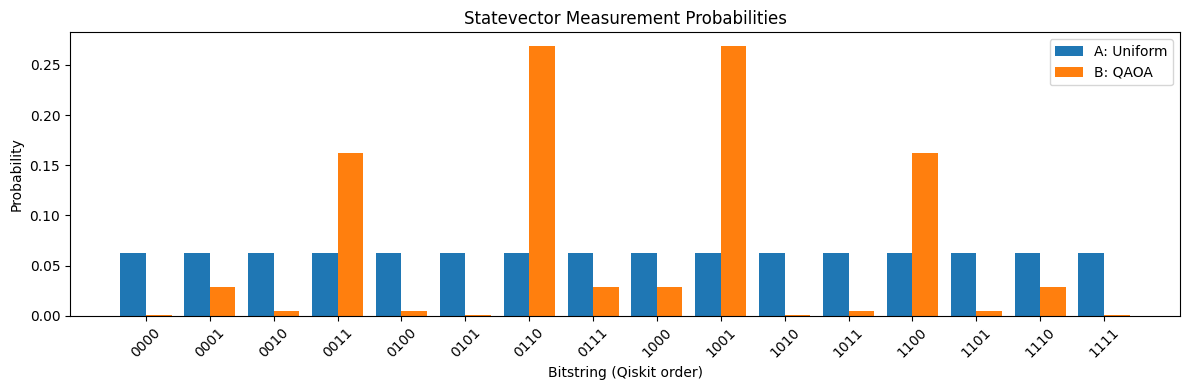

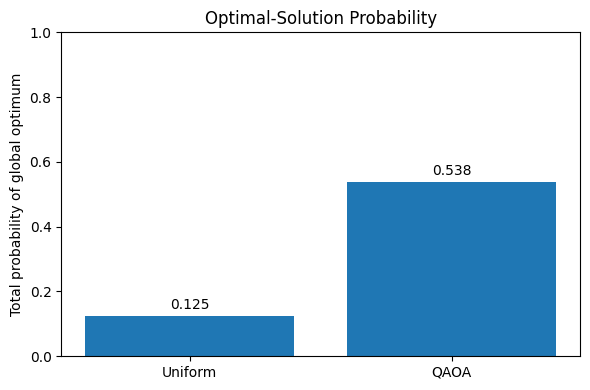

In [6]:
labels = [bitstr(i,N) for i in range(2**N)]
probability_table = pd.DataFrame({'bitstring':labels, 'qubo_energy':energies,
                                  'uniform_probability':prob_a, 'qaoa_probability':prob_b,
                                  'is_optimal':[i in opt_indices for i in range(2**N)]})
probability_table.to_csv(OUT/'state_probabilities.csv', index=False)
display(probability_table)

p_opt_a = float(prob_a[opt_indices].sum())
p_opt_b = float(prob_b[opt_indices].sum())
print(f'Uniform P(opt) = {p_opt_a:.4f}')
print(f'QAOA    P(opt) = {p_opt_b:.4f}')
print(f'Uniform E[QUBO] = {np.dot(prob_a, energies):.4f}')
print(f'QAOA    E[QUBO] = {np.dot(prob_b, energies):.4f}')

fig, ax = plt.subplots(figsize=(12,4))
xloc = np.arange(len(labels))
ax.bar(xloc-.2, prob_a, .4, label='A: Uniform')
ax.bar(xloc+.2, prob_b, .4, label='B: QAOA')
ax.set_xticks(xloc,labels,rotation=45)
ax.set(xlabel='Bitstring (Qiskit order)',ylabel='Probability',title='Statevector Measurement Probabilities')
ax.legend();fig.tight_layout();fig.savefig(OUT/'state_probabilities.png',dpi=160);plt.show()

fig,ax = plt.subplots(figsize=(6,4))
ax.bar(['Uniform','QAOA'], [p_opt_a,p_opt_b]);ax.set_ylim(0,1)
ax.set(ylabel='Total probability of global optimum',title='Optimal-Solution Probability')
for i,v in enumerate([p_opt_a,p_opt_b]):ax.text(i,v+.02,f'{v:.3f}',ha='center')
fig.tight_layout();fig.savefig(OUT/'optimal_probability.png',dpi=160);plt.show()

,algorithm,samples,best_energy,mean_sample_energy,optimal_sample_fraction,sampling_or_search_sec,training_sec,total_sec
0,Exact Search,1,-10.0,-10.000000,1.000000,0.000119,0.000000,0.000119
1,Random Sampling,1024,-10.0,-5.457031,0.110352,0.000558,0.000000,0.000558
2,Greedy Local Search,1024,-10.0,-9.630859,0.876953,0.004345,0.000000,0.004345
3,QAOA (Statevector samples),1024,-10.0,-7.653320,0.530273,0.000415,0.868063,0.868478


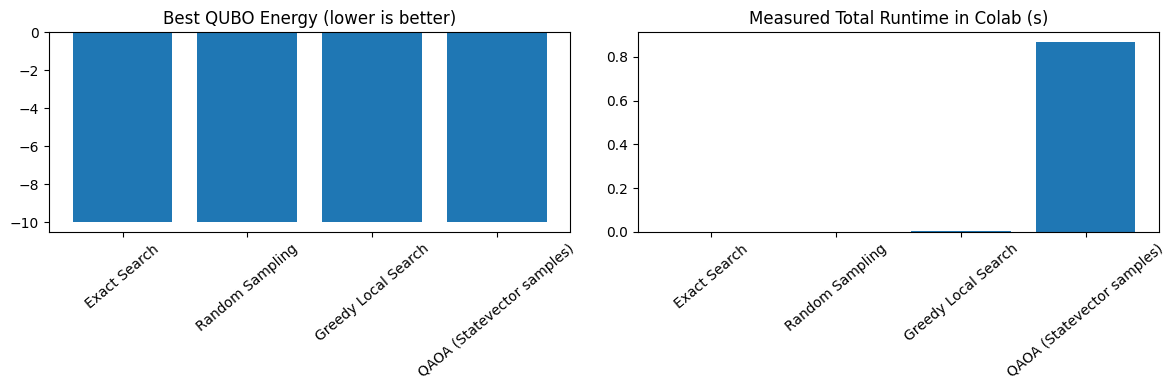

주의: Exact Search는 해를 1개 반환하므로 optimal_sample_fraction=1은 표본의 최적확률이 아닙니다.


In [7]:
SHOTS = 1024
rng = np.random.default_rng(SEED)

def greedy_one_flip(start, en, n):
    cur = int(start)
    while True:
        neighbors = [cur ^ (1 << i) for i in range(n)]
        nxt = min(neighbors, key=lambda k: en[k])
        if en[nxt] >= en[cur]-1e-12: return cur
        cur = nxt

t0=time.perf_counter()
exact_idx=int(np.argmin(energies))
exact_seconds=time.perf_counter()-t0

t0=time.perf_counter()
random_samples = rng.integers(0,2**N,size=SHOTS)
random_seconds=time.perf_counter()-t0

t0=time.perf_counter()
greedy_solutions=np.array([greedy_one_flip(s,energies,N) for s in rng.integers(0,2**N,size=SHOTS)])
greedy_seconds=time.perf_counter()-t0

t0=time.perf_counter()
qaoa_samples=rng.choice(2**N,size=SHOTS,p=prob_b)
qaoa_sample_seconds=time.perf_counter()-t0

# QAOA 시간에는 파라미터 학습 시간이 포함되도록 별도 기록
records=[]
for method, vals, t, setup in [
    ('Exact Search',np.array([exact_idx]),exact_seconds,0.0),
    ('Random Sampling',random_samples,random_seconds,0.0),
    ('Greedy Local Search',greedy_solutions,greedy_seconds,0.0),
    ('QAOA (Statevector samples)',qaoa_samples,qaoa_sample_seconds,qaoa_training_seconds),
]:
    records.append({'algorithm':method,'samples':len(vals),
                    'best_energy':float(energies[vals].min()),
                    'mean_sample_energy':float(energies[vals].mean()),
                    'optimal_sample_fraction':float(np.isin(vals,opt_indices).mean()),
                    'sampling_or_search_sec':t,'training_sec':setup,
                    'total_sec':t+setup})
comparison=pd.DataFrame(records)
comparison.to_csv(OUT/'qubo_comparison.csv',index=False)
display(comparison)

fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(comparison.algorithm,comparison.best_energy)
axes[0].set_title('Best QUBO Energy (lower is better)');axes[0].tick_params(axis='x',rotation=40)
axes[1].bar(comparison.algorithm,comparison.total_sec)
axes[1].set_title('Measured Total Runtime in Colab (s)');axes[1].tick_params(axis='x',rotation=40)
fig.tight_layout();fig.savefig(OUT/'algorithm_comparison.png',dpi=160);plt.show()
print('주의: Exact Search는 해를 1개 반환하므로 optimal_sample_fraction=1은 표본의 최적확률이 아닙니다.')

In [8]:
uniform_exp=float(np.dot(prob_a,energies))
qaoa_exp=float(np.dot(prob_b,energies))
report=f"""# Homework 3: Quantum Advantage for QUBO

## 1. Problem
We solve a weighted Max-Cut problem formulated as a QUBO minimization:

\[\min_{{x\in\{{0,1\}}^n}} x^TQx=-\sum_{{(i,j)\in E}}w_{{ij}}(x_i+x_j-2x_ix_j).\]

Number of qubits: {N}. Edges: {EDGES}.

QUBO matrix:
```text
{Q}
```

Exact optimal energy: **{optimum_energy:.3f}**. Optimal bitstrings: **{', '.join(bitstr(i,N) for i in opt_indices)}**.

## 2. Code and Quantum States
- State A: uniform superposition `H^n |0...0>`.
- State B: p=1 QAOA `U_B(beta) U_C(gamma) |+...+>`.
- Optimized parameters: gamma={gamma_opt:.6f}, beta={beta_opt:.6f}.
- Qiskit `Statevector.from_instruction` computed noiseless distributions.
- The Python Qiskit notebook and circuit figures are attached separately.

## 3. Comparisons
- Uniform P(optimum): **{p_opt_a:.6f}**.
- QAOA P(optimum): **{p_opt_b:.6f}**.
- Uniform expected QUBO energy: **{uniform_exp:.6f}**.
- QAOA expected QUBO energy: **{qaoa_exp:.6f}**.
- QAOA training time (Colab wall time): **{qaoa_training_seconds:.6f} s**, objective evaluations **{objective_calls['n']}**.

Algorithm result table:

{comparison.to_markdown(index=False)}

Figures: `circuit_A.png`, `circuit_B.png`, `state_probabilities.png`, `optimal_probability.png`, `algorithm_comparison.png` (when generated).

## 4. Explanations: Supremacy vs Advantage
Quantum supremacy usually emphasizes achieving a task beyond practical classical computational capability, potentially without direct application value. Quantum advantage emphasizes a demonstrable performance benefit on a specified task against classical baselines. Their use can overlap, so benchmark definitions matter.

The two circuits are **not** a supremacy-state and an advantage-state. They represent a uniform baseline state and a trained QAOA state for the same QUBO objective. The comparison establishes whether QAOA concentrates measurement probability on solutions with low QUBO energy; it does **not** by itself establish computational quantum advantage or supremacy.

## 5. Limitations and Conclusion
This study used {N} qubits and an ideal Qiskit Statevector simulator. Such small cases can be solved exactly by classical enumeration. The QAOA parameters were optimized classically, and simulation/classical overhead is included in measured runtime. Results depend on the selected instance, random seed, initial conditions and Colab runtime. Stronger evidence would require larger instances, multiple random seeds, physical device/noise studies, resource matching, and stronger classical baselines.

The defensible conclusion is that we measured the difference in solution distributions between the two quantum states and compared sample quality with classical approaches; no quantum supremacy or computational advantage claim is made from this experiment alone.
"""
(OUT/'homepage_report.md').write_text(report,encoding='utf-8')
print(report[:2500])

# Homework 3: Quantum Advantage for QUBO

## 1. Problem
We solve a weighted Max-Cut problem formulated as a QUBO minimization:

\[\min_{x\in\{0,1\}^n} x^TQx=-\sum_{(i,j)\in E}w_{ij}(x_i+x_j-2x_ix_j).\]

Number of qubits: 4. Edges: [(0, 1, 3.0), (0, 2, 2.0), (1, 2, 1.0), (1, 3, 2.0), (2, 3, 3.0)].

QUBO matrix:
```text
[[-5.  3.  2.  0.]
 [ 3. -6.  1.  2.]
 [ 2.  1. -6.  3.]
 [ 0.  2.  3. -5.]]
```

Exact optimal energy: **-10.000**. Optimal bitstrings: **0110, 1001**.

## 2. Code and Quantum States
- State A: uniform superposition `H^n |0...0>`.
- State B: p=1 QAOA `U_B(beta) U_C(gamma) |+...+>`.
- Optimized parameters: gamma=0.922990, beta=0.475145.
- Qiskit `Statevector.from_instruction` computed noiseless distributions.
- The Python Qiskit notebook and circuit figures are attached separately.

## 3. Comparisons
- Uniform P(optimum): **0.125000**.
- QAOA P(optimum): **0.538127**.
- Uniform expected QUBO energy: **-5.500000**.
- QAOA expected QUBO energy: **-7.702734**.
- QAOA trainin

<>:8: SyntaxWarning: invalid escape sequence '\{'
<>:8: SyntaxWarning: invalid escape sequence '\}'
<>:53: SyntaxWarning: invalid escape sequence '\['
<>:48: SyntaxWarning: invalid escape sequence '\i'
<>:48: SyntaxWarning: invalid escape sequence '\s'
<>:48: SyntaxWarning: invalid escape sequence '\i'
<>:48: SyntaxWarning: invalid escape sequence '\]'
<>:8: SyntaxWarning: invalid escape sequence '\{'
<>:8: SyntaxWarning: invalid escape sequence '\}'
<>:53: SyntaxWarning: invalid escape sequence '\['
<>:48: SyntaxWarning: invalid escape sequence '\i'
<>:48: SyntaxWarning: invalid escape sequence '\s'
<>:48: SyntaxWarning: invalid escape sequence '\i'
<>:48: SyntaxWarning: invalid escape sequence '\]'
/tmp/ipykernel_4552/3995771261.py:8: SyntaxWarning: invalid escape sequence '\{'
  \[\min_{{x\in\{{0,1\}}^n}} x^TQx=-\sum_{{(i,j)\in E}}w_{{ij}}(x_i+x_j-2x_ix_j).\]
/tmp/ipykernel_4552/3995771261.py:8: SyntaxWarning: invalid escape sequence '\}'
  \[\min_{{x\in\{{0,1\}}^n}} x^TQx=-\sum_{{(

In [9]:
from zipfile import ZipFile
zip_path=Path('QUBO_Homework3_RESULTS.zip')
with ZipFile(zip_path,'w') as z:
    for file in OUT.iterdir():
        if file.is_file():z.write(file,arcname=file.name)
print('Created:',zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('Colab 이외의 환경입니다. ZIP은 현재 폴더에 저장되었습니다.')

Created: QUBO_Homework3_RESULTS.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>